In [3]:
import math
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import librosa
import IPython

/var/folders/hy/kl7wj11525l7dzlfzm123s_c0000gn/T/ipykernel_47002/2932074989.py:11: FutureWarning: waveshow() keyword argument 'x_axis' has been renamed to 'axis' in version 0.10.0.
	This alias will be removed in version 1.0.
  librosa.display.waveshow(audio_sound, sr=sr, ax=ax,x_axis='time')


[Text(0.5, 1.0, 'The sound waveform'),
 Text(0.5, 3.722222222222216, 'Time [s]')]

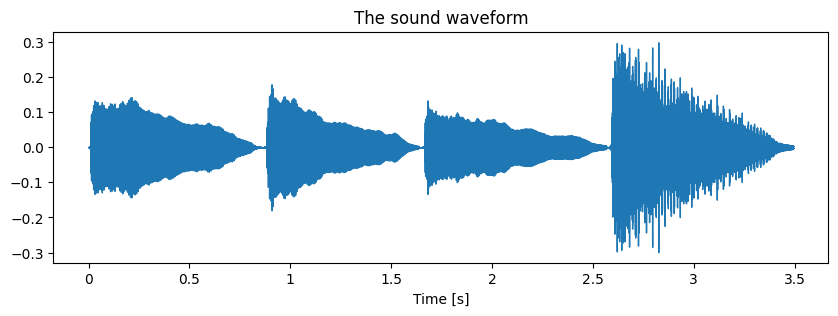

In [4]:
audio_file = 'piano_mix.wav'

sample_rate = 5512
# Load audio signal
audio_sound, sr = librosa.load(audio_file, sr = sample_rate)
# Display audio
IPython.display.display(IPython.display.Audio(audio_sound,rate = sr))

# Plotting the sound's waveform
fig, ax = plt.subplots(figsize=(10, 3))
librosa.display.waveshow(audio_sound, sr=sr, ax=ax,x_axis='time')
ax.set(title='The sound waveform',
       xlabel='Time [s]')

Text(0.5, 1.0, 'Audio spectrogram')

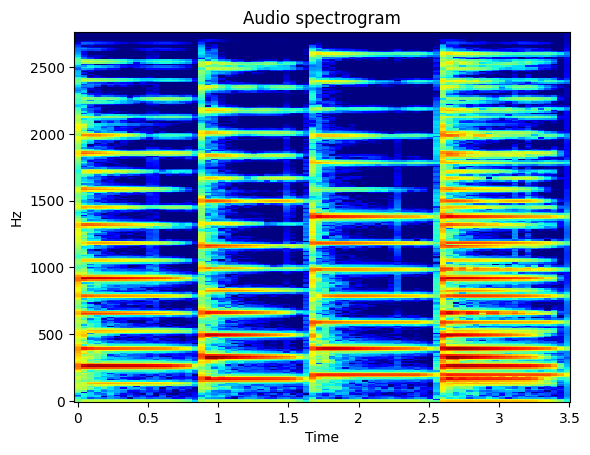

In [5]:
FRAME = 512
HOP = 256

# Return the complex Short Term Fourier Transform
sound_stft = librosa.stft(audio_sound, n_fft = FRAME, hop_length = HOP)

# Magnitude Spectrogram
sound_stft_Magnitude = np.abs(sound_stft)

#Plot Spectogram
Spec = librosa.amplitude_to_db(sound_stft_Magnitude, ref = np.max)
librosa.display.specshow(Spec,y_axis = 'hz',sr=sr,hop_length=HOP,x_axis ='time',cmap= matplotlib.cm.jet)
plt.title('Audio spectrogram')

In [6]:
epsilon = 1e-10 # error to introduce
V = sound_stft_Magnitude + epsilon
K, N = np.shape(V)
S = 3 
print(f"S = {S} : Number of Sources to separate")

S = 3 : Number of Sources to separate


In [7]:
def divergence(V,W,H, beta = 2):
    
    """
    beta = 2 : Euclidean cost function
    beta = 1 : Kullback-Leibler cost function
    beta = 0 : Itakura-Saito cost function
    """ 
    
    if beta == 0 : return np.sum( V/(W@H) - np.log10(V/(W@H)) -1 )
    
    if beta == 1 : return np.sum( V*np.log10(V/(W@H)) + (W@H - V))
    
    if beta == 2 : return 1/2*np.linalg.norm(W@H-V)

  0%|          | 0/1000 [00:00<?, ?it/s]

Iteration 0 : Divergence = 693.8013755138854


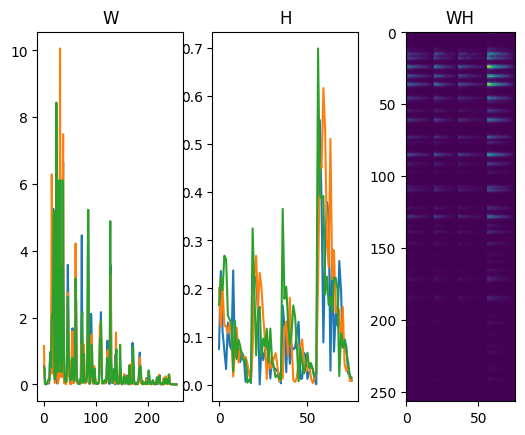

  0%|          | 1/1000 [00:00<04:55,  3.38it/s]

Iteration 100 : Divergence = 139.36256202942502


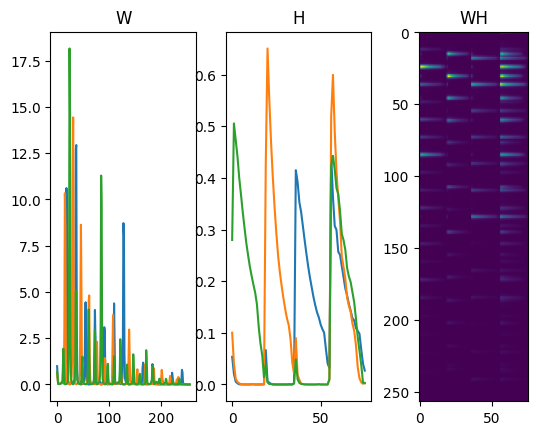

 10%|█         | 101/1000 [00:00<00:04, 208.94it/s]

Iteration 200 : Divergence = 139.3622033480919


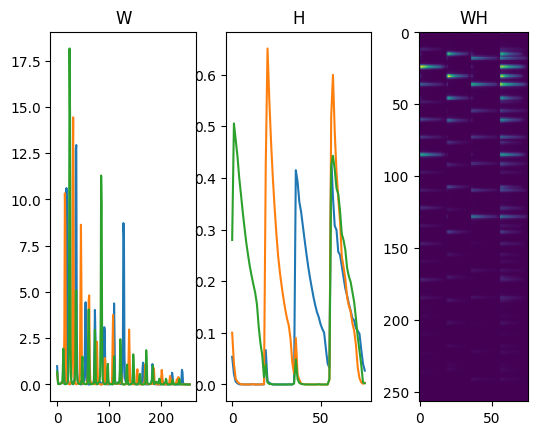

 20%|██        | 201/1000 [00:00<00:03, 258.24it/s]

Iteration 300 : Divergence = 139.3620485902142


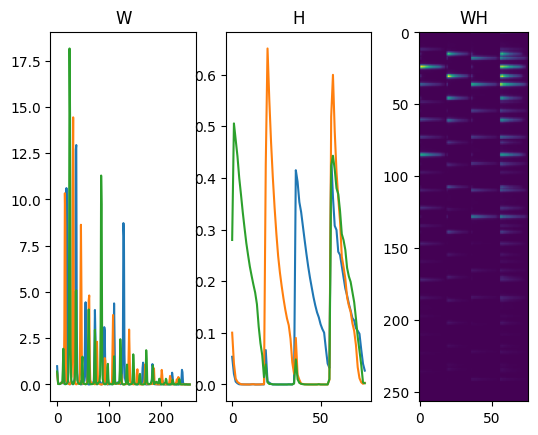

 30%|███       | 301/1000 [00:01<00:02, 296.16it/s]

Iteration 400 : Divergence = 139.36203664171634


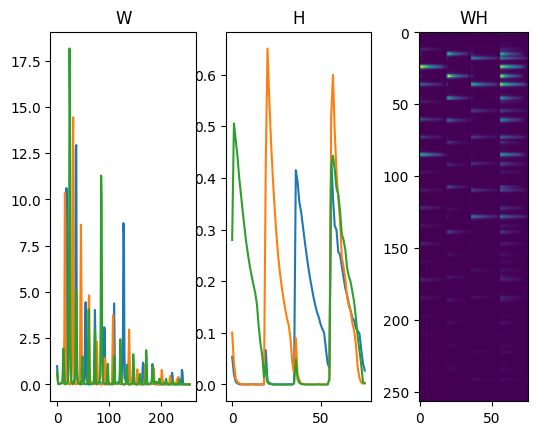

 40%|████      | 401/1000 [00:01<00:02, 260.93it/s]

Iteration 500 : Divergence = 139.3620153204043


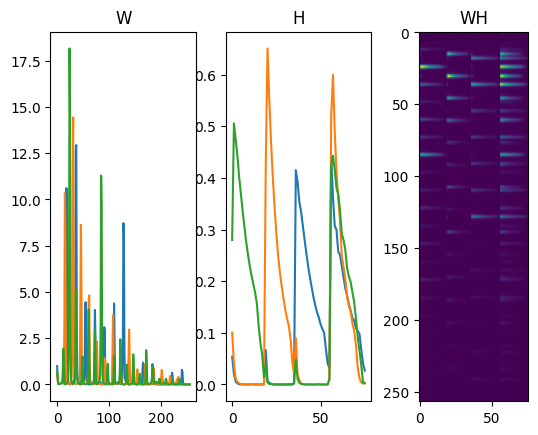

 50%|█████     | 501/1000 [00:01<00:01, 288.98it/s]

Iteration 600 : Divergence = 139.36201257399654


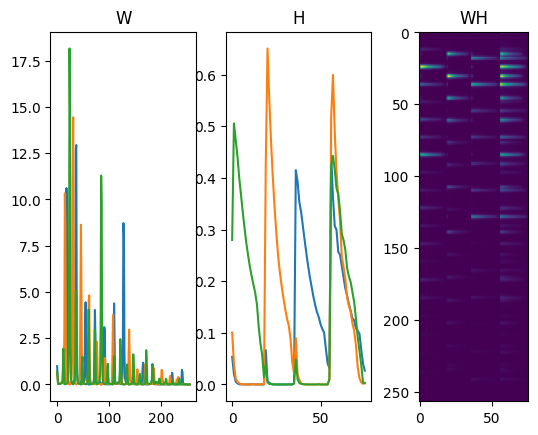

 60%|██████    | 601/1000 [00:02<00:01, 296.22it/s]

Iteration 700 : Divergence = 139.36201185168497


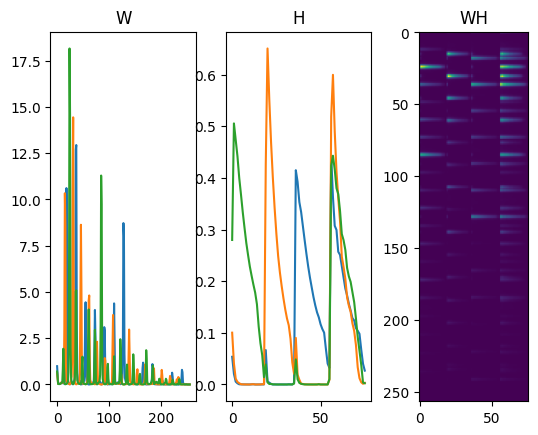

 70%|███████   | 701/1000 [00:02<00:00, 315.72it/s]

Iteration 800 : Divergence = 139.3620116266262


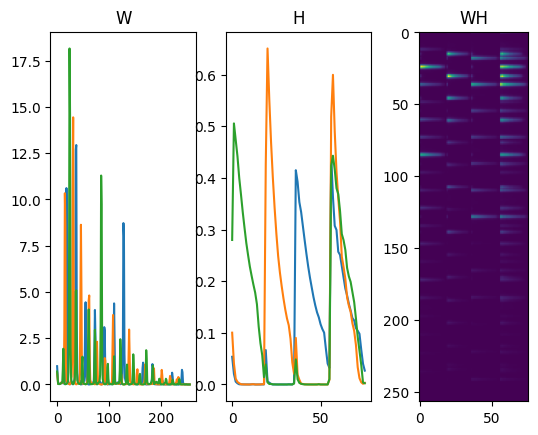

 80%|████████  | 801/1000 [00:02<00:00, 315.39it/s]

Iteration 900 : Divergence = 139.36201155904973


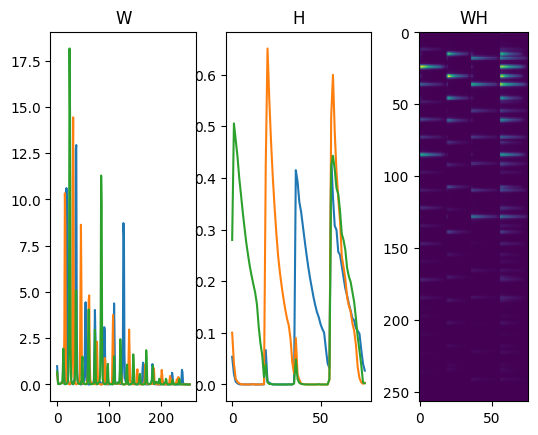

100%|██████████| 1000/1000 [00:03<00:00, 314.34it/s]


In [8]:
from tqdm import tqdm

W_ks = np.random.rand(K,S)
H_sn = np.random.rand(S,N)

beta = 1
for iter in tqdm(np.arange(1000)):
    H_sn = H_sn * (W_ks.T @ (V*(W_ks@H_sn)**(beta-2)) / (W_ks.T @ (W_ks@H_sn)**(beta-1)))
    W_ks = W_ks * (((V*(W_ks@H_sn)**(beta-2)) @ H_sn.T) / (((W_ks@H_sn)**(beta-1))@H_sn.T))

    if iter % 100 == 0:
        print(f"Iteration {iter} : Divergence = {divergence(V,W_ks,H_sn,beta)}")

        # if subplot is needed
        plt.subplot(1,3,1)
        plt.plot(W_ks)
        plt.title('W')
        plt.subplot(1,3,2)
        plt.plot(H_sn.T)
        plt.title('H')
        plt.subplot(1,3,3)
        plt.imshow(W_ks@H_sn)
        plt.title('WH')
        plt.show()


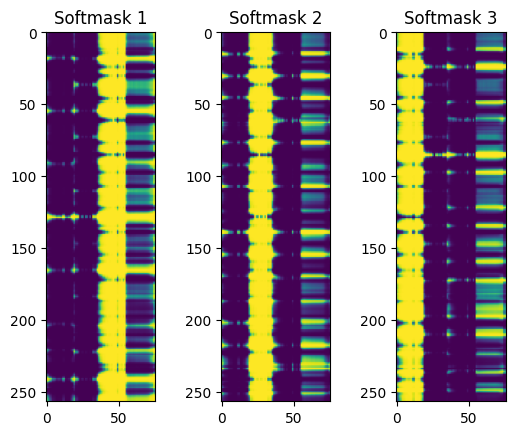

In [ ]:
# Get the softmask  
V2 = W_ks @ H_sn

for s in range(S):
    softmask = (W_ks[:,s][:,np.newaxis] @ H_sn[s,:][np.newaxis,:]) / V2
    plt.subplot(1,S,s+1)
    plt.imshow(softmask)
    plt.title(f'Softmask {s+1}')

    source_s = softmask * sound_stft
    source_s = librosa.istft(source_s, hop_length = HOP)
    IPython.display.display(IPython.display.Audio(source_s,rate = sr))
plt.show()  